<a href="https://colab.research.google.com/github/peeyush211/ML-Lab/blob/main/Random_Forest_Lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lab 6**

**Aim - Create Random forest for classification on sample dataset**

**Peeyush Agarwal 2427010184 AIM3130**


In [ ]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [ ]:
# Load the dataset
df = pd.read_csv("BankNoteAuthentication.csv")

In [ ]:
print(df.head()) # Display first five rows
print(df.info()) # Check dataset information
print(df.isnull().sum()) # Check for missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [ ]:
# Separate input features and target
X = df.drop('class', axis=1)
y = df['class']

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X , y, test_size = 0.2 , random_state = 42)

In [ ]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1097, 4)
X_test : (275, 4)
y_train: (1097,)
y_test : (275,)


In [ ]:
# Create Random Forest model
rf = RandomForestClassifier(n_estimators=100,max_depth=5, random_state=42)

In [ ]:
rf.fit(X_train, y_train)  # Train the model
y_pred = rf.predict(X_test)  # Make predictions
print(y_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [ ]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)

Accuracy : 0.9818181818181818
Precision: 0.9765625
Recall   : 0.984251968503937


In [ ]:
# Experiment with different tree depths
depths = [2, 3, 5, 7, 10]
results_depth = []
for depth in depths:
    rf = RandomForestClassifier(n_estimators=100,max_depth=depth,random_state=42)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    results_depth.append([depth,accuracy,precision,recall])

In [ ]:
results_depth_df = pd.DataFrame(
    results_depth,
    columns=['Max Depth', 'Accuracy', 'Precision', 'Recall']
)

results_depth_df

,Max Depth,Accuracy,Precision,Recall
0,2,0.916364,0.956140,0.858268
1,3,0.938182,0.958333,0.905512
2,5,0.981818,0.976562,0.984252
3,7,0.989091,0.992063,0.984252
4,10,0.992727,1.000000,0.984252


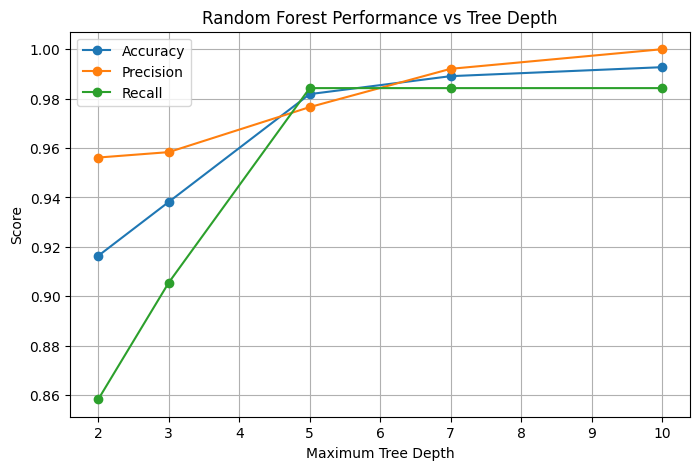

In [ ]:
# Plot performance vs tree depth
plt.figure(figsize=(8, 5))
plt.plot(results_depth_df['Max Depth'], results_depth_df['Accuracy'],
         marker='o', label='Accuracy')
plt.plot(results_depth_df['Max Depth'], results_depth_df['Precision'],
         marker='o', label='Precision')
plt.plot(results_depth_df['Max Depth'], results_depth_df['Recall'],
         marker='o', label='Recall')
plt.xlabel('Maximum Tree Depth')
plt.ylabel('Score')
plt.title('Random Forest Performance vs Tree Depth')
plt.legend()
plt.grid(True)
plt.show()